# 01 — Breast Cancer Biomarker Discovery and Classification

**Author:** Samuel Molina  
**Data:** Breast cancer RNA-seq gene expression matrix (1,191 samples × 56,937 genes; Tumor vs Normal)

Machine-learning biomarker discovery pipeline adapted from Figure 1(A–B) of Syed et al. (2024):

1. Data loading and preprocessing
2. Part 1 — Differential expression (DEG) analysis, visualization, multi-method feature selection and a consensus biomarker panel
3. Part 2 — Classifier benchmarking on the screened biomarkers
4. Part 3 — Attempted external validation on GEO cohort GSE75214
5. Conclusion and known limitations

> Originally developed for coursework (DANA 4840, Langara College) and extended as a portfolio project. See the repository README for known limitations.

## 0. Import Libraries

This section imports the libraries needed for data processing, visualization, feature selection, and machine learning modeling.

In [14]:
# Basic libraries
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)
from sklearn.feature_selection import mutual_info_classif, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 51
np.random.seed(RANDOM_STATE)

## 1. Load the Provided Dataset

The provided files are:

- `X_data_full.csv`: gene expression matrix
- `y_data_full.csv`: class labels

The target variable is expected to contain two classes: **Tumor** and **Normal**.

In [2]:
# Change these paths if your files are stored in a different folder
X_path = "X_data_full.csv"
y_path = "y_data_full.csv"

X = pd.read_csv(X_path)
y = pd.read_csv(y_path)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("First rows of X:")
display(X.head())

print("First rows of y:")
display(y.head())

print("Class distribution:")
print(y.iloc[:, 0].value_counts())

X shape: (1191, 56937)
y shape: (1191, 1)
First rows of X:


,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2,GCLC,NFYA,...,AC010980.1,AC007511.1,AC004233.4,AC092910.4,AC073611.1,AC078856.1,AC008763.4,AL592295.6,AL391628.1,AP006621.6
0,4474,9,1785,1362,433,928,2445,4487,2278,2511,...,10,0,0,0,27,0,0,150,6,21
1,3555,30,2537,1865,890,711,4352,2175,2472,3796,...,8,0,0,0,38,0,0,590,11,28
2,731,113,5947,3118,1063,460,4609,4547,2265,4388,...,133,0,0,3,60,0,0,754,14,31
3,3960,50,2155,1355,474,237,2440,2270,2637,1914,...,5,0,0,0,18,0,0,332,9,31
4,3834,0,3161,1411,637,468,4472,2588,1601,1585,...,1,0,1,0,8,0,0,354,0,13


First rows of y:


,Sample
0,Tumor
1,Tumor
2,Tumor
3,Tumor
4,Tumor


Class distribution:
Sample
Tumor     1080
Normal     111
Name: count, dtype: int64


## 2. Basic Cleaning and Label Encoding

This section checks missing values, converts labels into numeric format, and applies a log transformation to reduce extreme expression values.

In [3]:
# Target column
label_col = y.columns[0]

# Make sure X contains only numeric values
X = X.apply(pd.to_numeric, errors='coerce')

# Fill missing values using column medians
X = X.fillna(X.median(numeric_only=True))

# Encode labels: Normal/Tumor -> 0/1 or 1/0 depending on alphabetical order
le = LabelEncoder()
y_encoded = le.fit_transform(y[label_col])

print("Label mapping:")
for cls, code_value in zip(le.classes_, le.transform(le.classes_)):
    print(f"{cls}: {code_value}")

# Log2 transform gene expression values
X_log = np.log2(X + 1)

print("X_log shape:", X_log.shape)

Label mapping:
Normal: 0
Tumor: 1
X_log shape: (1191, 56937)


## 3. Random Under-Sampling

The dataset is heavily imbalanced (1,080 Tumor vs 111 Normal). The Tumor class is randomly under-sampled to match the Normal class, which reduces computational cost and gives a balanced Tumor/Normal comparison.

In [5]:
# Combine X and y for sampling
full_df = X_log.copy()
full_df["target"] = y_encoded

# Separate classes
normal_df = full_df[full_df["target"] == 0]
tumor_df = full_df[full_df["target"] == 1]

print("Normal samples:", normal_df.shape[0])
print("Tumor samples:", tumor_df.shape[0])

# Under-sample tumor class to match normal class
tumor_sampled = tumor_df.sample(n=normal_df.shape[0], random_state=RANDOM_STATE)

# Combine balanced data
balanced_df = pd.concat([normal_df, tumor_sampled], axis=0)
balanced_df = balanced_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

X_bal = balanced_df.drop("target", axis=1)
y_bal = balanced_df["target"]

print("Balanced X shape:", X_bal.shape)
print("Balanced class distribution:")
print(y_bal.value_counts())

Normal samples: 111
Tumor samples: 1080
Balanced X shape: (222, 56937)
Balanced class distribution:
target
0    111
1    111
Name: count, dtype: int64


# Part 1 — DEG Identification, Visualization, Feature Selection, and Biomarkers

The goal of Part 1 is to replicate the biomarker discovery workflow proposed in Figure 1(A) of the reference paper.

The required components are:

- Identification of differentially expressed genes (DEGs)
- Visualization of selected DEGs
- Feature selection using Mutual Information, RFECV, Elastic Net, and Gradient Boosting Classifier
- Final screened biomarkers for Breast Cancer

## 4. Identification of Differentially Expressed Genes (DEGs)

This section compares gene expression between the two classes using an independent t-test. It also calculates fold change and adjusted p-values using the Benjamini-Hochberg method.

Genes are classified as:

- **Upregulated**: significantly higher in Tumor
- **Downregulated**: significantly lower in Tumor
- **Non-significant**

In [8]:
# Identify which numeric label corresponds to Tumor and Normal
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(label_mapping)

# Try to automatically find tumor and normal labels
if 'Tumor' in label_mapping and 'Normal' in label_mapping:
    tumor_label = label_mapping['Tumor']
    normal_label = label_mapping['Normal']
else:
    # Fallback: use the second class as positive class
    normal_label = 0
    tumor_label = 1

X_tumor = X_bal[y_bal == tumor_label]
X_normal = X_bal[y_bal == normal_label]

# Vectorized t-test for every gene
t_stats, p_values = ttest_ind(X_tumor, X_normal, axis=0, equal_var=False, nan_policy='omit')

# Replace NaN p-values with 1
p_values = np.nan_to_num(p_values, nan=1.0)

# Adjust p-values
_, q_values, _, _ = multipletests(p_values, method='fdr_bh')

# Mean expression by class
mean_tumor = X_tumor.mean(axis=0)
mean_normal = X_normal.mean(axis=0)

# Difference and fold change on log scale
log2_fold_change = mean_tumor - mean_normal

# DEG thresholds
q_threshold = 0.05
log2fc_threshold = 1.0

category = np.where(
    (q_values < q_threshold) & (log2_fold_change > log2fc_threshold), 'Upregulated',
    np.where((q_values < q_threshold) & (log2_fold_change < -log2fc_threshold), 'Downregulated', 'Non-significant')
)

deg_results = pd.DataFrame({
    'Gene': X_bal.columns,
    't_statistic': t_stats,
    'p_value': p_values,
    'q_value': q_values,
    'mean_tumor': mean_tumor.values,
    'mean_normal': mean_normal.values,
    'log2_fold_change': log2_fold_change.values,
    'Category': category
})

deg_results = deg_results.sort_values('q_value')

print("DEG category counts:")
print(deg_results['Category'].value_counts())

display(deg_results.head(20))

# Save DEG results
os.makedirs('outputs', exist_ok=True)
deg_results.to_csv('outputs/deg_results.csv', index=False)

{'Normal': np.int64(0), 'Tumor': np.int64(1)}
DEG category counts:
Category
Non-significant    49713
Downregulated       4808
Upregulated         2416
Name: count, dtype: int64


,Gene,t_statistic,p_value,q_value,mean_tumor,mean_normal,log2_fold_change,Category
2138,MMP11,31.769597,1.893592e-75,1.078154e-70,13.899943,8.037625,5.862318,Upregulated
5385,COL10A1,29.470365,5.006056e-73,1.425149e-68,12.217310,5.333405,6.883904,Upregulated
12059,CA4,-28.040162,3.814952e-69,7.240397e-65,2.692120,9.709861,-7.017741,Downregulated
1939,CPA1,-26.233021,1.291111e-68,1.690080e-64,1.613214,6.468948,-4.855734,Downregulated
27394,LINC00377,-26.937689,1.484166e-68,1.690080e-64,0.892846,4.532379,-3.639533,Downregulated
24579,PGM5-AS1,-25.184869,1.615714e-65,1.533232e-61,1.377565,5.532594,-4.155030,Downregulated
28470,LINC01614,24.881921,9.895905e-65,8.049188e-61,7.619683,2.160109,5.459575,Upregulated
11519,VEGFD,-28.032281,2.631723e-64,1.873030e-60,4.439168,10.641690,-6.202521,Downregulated
46840,AP005264.1,-24.161649,1.558568e-63,9.860021e-60,1.520150,4.967402,-3.447252,Downregulated
5512,HIF3A,-26.261054,1.320651e-62,7.519391e-59,4.025839,9.367971,-5.342132,Downregulated


## 5. Top Upregulated and Downregulated Genes

This table summarizes the most significant genes in each DEG category.

In [7]:
top_upregulated = deg_results[deg_results['Category'] == 'Upregulated'].head(20)
top_downregulated = deg_results[deg_results['Category'] == 'Downregulated'].head(20)

print("Top upregulated genes:")
display(top_upregulated)

print("Top downregulated genes:")
display(top_downregulated)

top_upregulated.to_csv('outputs/top_upregulated_genes.csv', index=False)
top_downregulated.to_csv('outputs/top_downregulated_genes.csv', index=False)

Top upregulated genes:


,Gene,t_statistic,p_value,q_value,mean_tumor,mean_normal,log2_fold_change,Category


Top downregulated genes:


,Gene,t_statistic,p_value,q_value,mean_tumor,mean_normal,log2_fold_change,Category


## 6. Visualization 1 — Volcano Plot

The volcano plot shows the relationship between fold change and statistical significance.

- Genes on the right are more expressed in Tumor.
- Genes on the left are more expressed in Normal.
- Genes higher on the plot are more statistically significant.

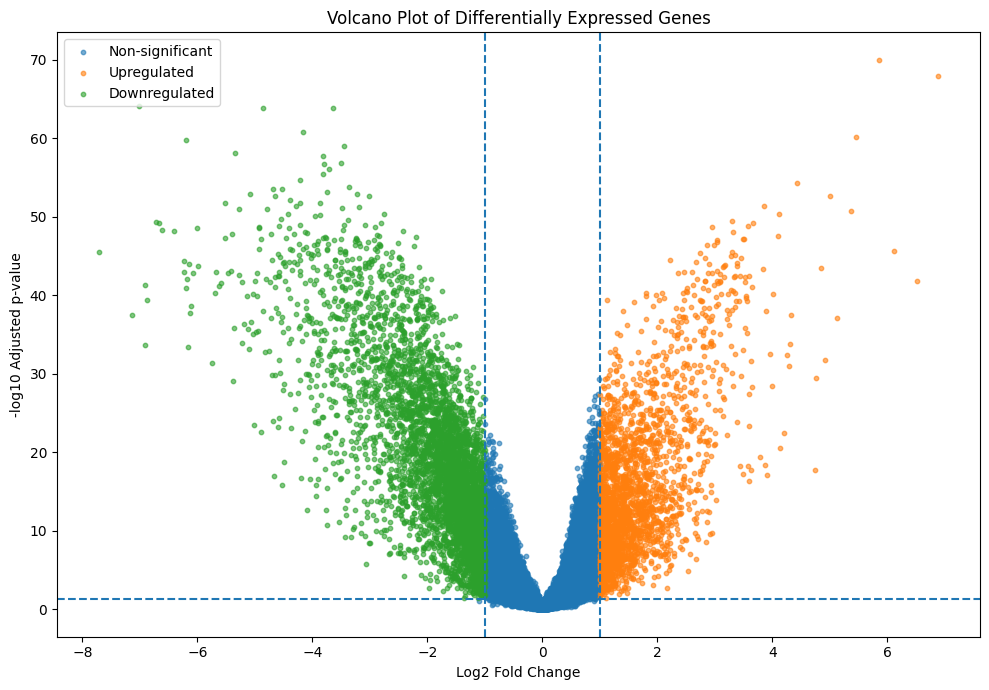

In [9]:
plot_df = deg_results.copy()
plot_df['minus_log10_q'] = -np.log10(plot_df['q_value'].replace(0, np.nextafter(0, 1)))

plt.figure(figsize=(10, 7))
for cat in ['Non-significant', 'Upregulated', 'Downregulated']:
    subset = plot_df[plot_df['Category'] == cat]
    plt.scatter(subset['log2_fold_change'], subset['minus_log10_q'], s=10, alpha=0.6, label=cat)

plt.axvline(log2fc_threshold, linestyle='--')
plt.axvline(-log2fc_threshold, linestyle='--')
plt.axhline(-np.log10(q_threshold), linestyle='--')
plt.xlabel('Log2 Fold Change')
plt.ylabel('-log10 Adjusted p-value')
plt.title('Volcano Plot of Differentially Expressed Genes')
plt.legend()
plt.tight_layout()
plt.savefig('outputs/volcano_plot.png', dpi=300)
plt.show()

## 7. Visualization 2 — Heatmap of Top DEGs

This heatmap shows expression patterns for the top selected DEGs across samples.

Selected genes: 50
Genes found in X_bal: 50
Heatmap data shape: (50, 222)


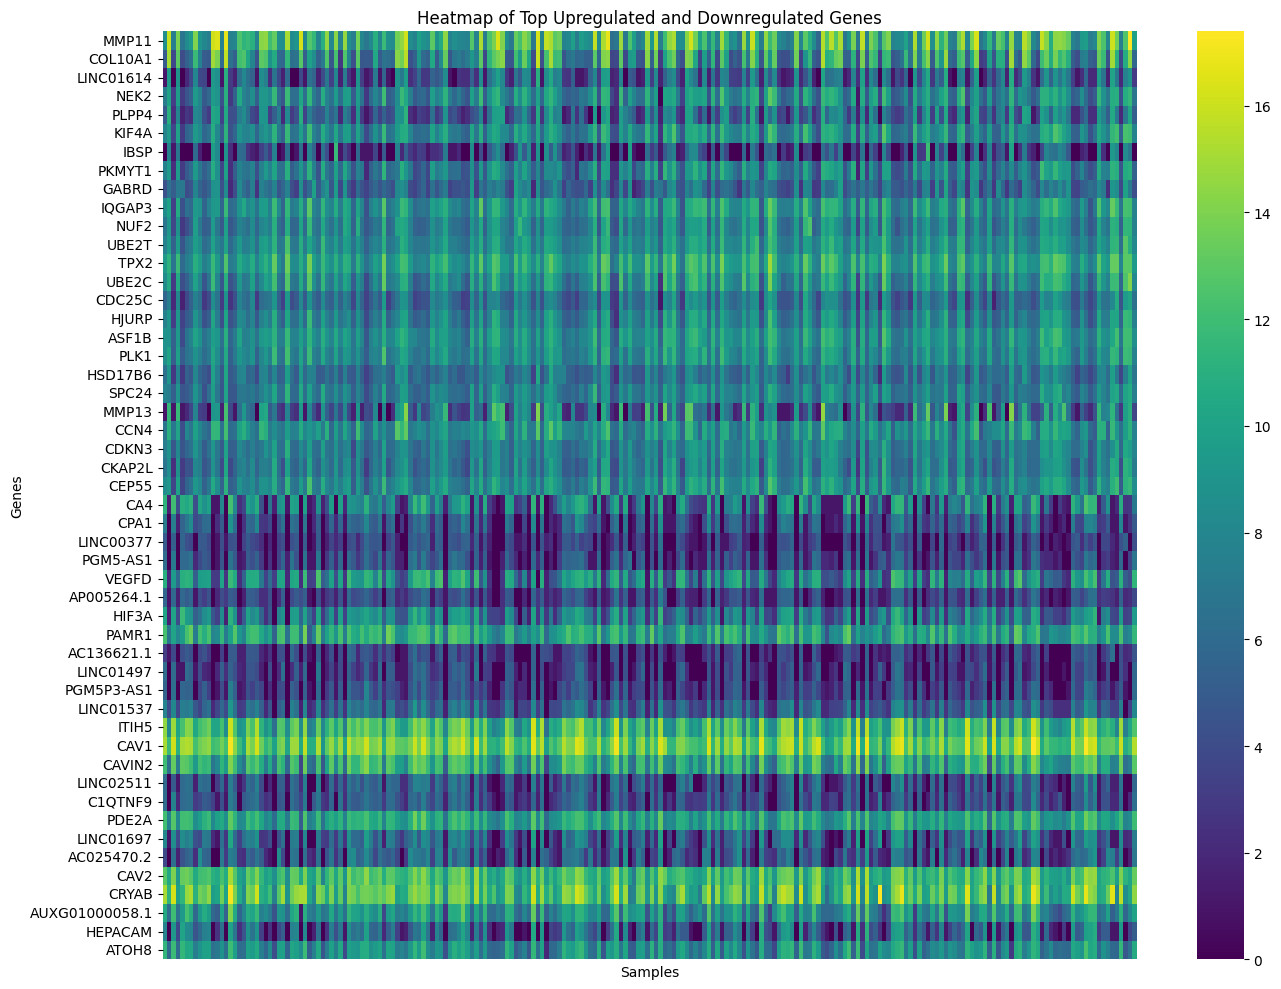

In [15]:
top_up_genes = (
    deg_results[deg_results["Category"] == "Upregulated"]
    .sort_values("q_value")
    .head(25)["Gene"]
    .tolist()
)

top_down_genes = (
    deg_results[deg_results["Category"] == "Downregulated"]
    .sort_values("q_value")
    .head(25)["Gene"]
    .tolist()
)

top_genes = top_up_genes + top_down_genes

print("Selected genes:", len(top_genes))
print("Genes found in X_bal:", sum(g in X_bal.columns for g in top_genes))

heatmap_data = X_bal[top_genes].T

print("Heatmap data shape:", heatmap_data.shape)

plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_data, cmap="viridis", xticklabels=False, yticklabels=True)
plt.title("Heatmap of Top Upregulated and Downregulated Genes")
plt.xlabel("Samples")
plt.ylabel("Genes")
plt.tight_layout()
plt.show()

## 8. Prepare DEG Subset for Feature Selection

To reduce computational cost, feature selection is applied only to the most significant DEG candidates.

In [16]:
# Use significant genes first. If too few are found, use top genes by q-value.
significant_genes = deg_results[deg_results['Category'] != 'Non-significant']['Gene'].tolist()

if len(significant_genes) < 50:
    significant_genes = deg_results.head(500)['Gene'].tolist()
else:
    significant_genes = significant_genes[:1000]

X_fs = X_bal[significant_genes]

print("Number of genes used for feature selection:", X_fs.shape[1])
print("X_fs shape:", X_fs.shape)

Number of genes used for feature selection: 1000
X_fs shape: (222, 1000)


## 9. Feature Selection Method 1 — Mutual Information

Mutual Information is a filter-based method that ranks genes according to their dependency with the target class.

In [17]:
mi_scores = mutual_info_classif(X_fs, y_bal, random_state=RANDOM_STATE)

mi_df = pd.DataFrame({
    'Gene': X_fs.columns,
    'MI_score': mi_scores
}).sort_values('MI_score', ascending=False)

mi_selected = mi_df.head(20)['Gene'].tolist()

print("Top Mutual Information genes:")
display(mi_df.head(20))
mi_df.to_csv('outputs/mutual_information_feature_selection.csv', index=False)

Top Mutual Information genes:


,Gene,MI_score
0,MMP11,0.613621
117,TSLP,0.608967
2,CA4,0.605964
7,VEGFD,0.597763
3,CPA1,0.592595
45,CD300LG,0.588372
1,COL10A1,0.588020
18,CAVIN2,0.580228
33,ADAMTS5,0.574024
124,MYOM1,0.572625


## 10. Feature Selection Method 2 — RFECV

RFECV is a wrapper-based feature selection method. It recursively removes less useful features and uses cross-validation to estimate performance.

To keep the computation manageable, RFECV is applied to the top 100 Mutual Information genes.

In [18]:
# RFECV can be slow, so use top 100 MI genes
rfecv_candidates = mi_df.head(100)['Gene'].tolist()
X_rfecv = X_fs[rfecv_candidates]

rf_estimator = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight='balanced'
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rfecv = RFECV(
    estimator=rf_estimator,
    step=0.1,
    min_features_to_select=10,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

rfecv.fit(X_rfecv, y_bal)

rfecv_selected = list(X_rfecv.columns[rfecv.support_])

print("Number of RFECV selected genes:", len(rfecv_selected))
print(rfecv_selected)

rfecv_df = pd.DataFrame({
    'Gene': X_rfecv.columns,
    'Selected_RFECV': rfecv.support_,
    'Ranking': rfecv.ranking_
}).sort_values(['Selected_RFECV', 'Ranking'], ascending=[False, True])

rfecv_df.to_csv('outputs/rfecv_feature_selection.csv', index=False)
display(rfecv_df.head(30))

Number of RFECV selected genes: 30
['MMP11', 'TSLP', 'CA4', 'VEGFD', 'CPA1', 'CD300LG', 'COL10A1', 'CAVIN2', 'SPRY2', 'HIF3A', 'NKAPL', 'LMOD1', 'MAMDC2', 'ITIH5', 'SLC2A4', 'CRYAB', 'SCARA5', 'AUXG01000058.1', 'MATN2', 'TMEM220', 'C1QTNF9', 'LINC00377', 'S100B', 'PPP1R14A', 'PLA2G4A', 'GABRD', 'MRAS', 'NTRK2', 'SYNM', 'LRRC3B']


,Gene,Selected_RFECV,Ranking
0,MMP11,True,1
1,TSLP,True,1
2,CA4,True,1
3,VEGFD,True,1
4,CPA1,True,1
5,CD300LG,True,1
6,COL10A1,True,1
7,CAVIN2,True,1
10,SPRY2,True,1
11,HIF3A,True,1


## 11. Feature Selection Method 3 — Elastic Net

Elastic Net is an embedded feature selection method. It combines L1 and L2 regularization and can shrink some coefficients to zero.

In [19]:
elastic_model = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    l1_ratio=0.5,
    C=0.5,
    max_iter=5000,
    random_state=RANDOM_STATE,
    class_weight='balanced'
)

elastic_model.fit(X_fs, y_bal)

coef = elastic_model.coef_[0]
elastic_df = pd.DataFrame({
    'Gene': X_fs.columns,
    'Coefficient': coef,
    'Abs_Coefficient': np.abs(coef)
}).sort_values('Abs_Coefficient', ascending=False)

elastic_selected = elastic_df[elastic_df['Abs_Coefficient'] > 0].head(20)['Gene'].tolist()

print("Top Elastic Net genes:")
display(elastic_df.head(20))
elastic_df.to_csv('outputs/elastic_net_feature_selection.csv', index=False)

Top Elastic Net genes:


,Gene,Coefficient,Abs_Coefficient
1,COL10A1,0.117748,0.117748
782,PITX1,0.080860,0.080860
273,CST1,0.075880,0.075880
605,SPHKAP,-0.073936,0.073936
191,SLC24A2,0.072924,0.072924
6,LINC01614,0.070960,0.070960
0,MMP11,0.067700,0.067700
340,PLAC1,0.066610,0.066610
475,CST2,0.066559,0.066559
7,VEGFD,-0.064381,0.064381


## 12. Feature Selection Method 4 — Gradient Boosting Classifier

Gradient Boosting is an embedded method that ranks features using feature importance from boosted decision trees.

In [20]:
gbc = GradientBoostingClassifier(random_state=RANDOM_STATE)
gbc.fit(X_fs, y_bal)

gbc_df = pd.DataFrame({
    'Gene': X_fs.columns,
    'Importance': gbc.feature_importances_
}).sort_values('Importance', ascending=False)

gbc_selected = gbc_df.head(20)['Gene'].tolist()

print("Top Gradient Boosting genes:")
display(gbc_df.head(20))
gbc_df.to_csv('outputs/gradient_boosting_feature_selection.csv', index=False)

Top Gradient Boosting genes:


,Gene,Importance
0,MMP11,0.912606
817,GLRA4,0.018881
22,LINC01697,0.017009
729,AL358332.1,0.015328
901,ALX4,0.007052
256,ANGPT4,0.005432
117,TSLP,0.003573
316,SPAAR,0.003321
538,LINC02408,0.002994
247,ABCA8,0.002186


## 13. Final Screened Biomarkers

The final biomarker list is created by combining the genes selected by the four feature selection methods. Genes selected by multiple methods are prioritized.

In [22]:
from collections import Counter

selection_lists = {
    'Mutual Information': mi_selected,
    'RFECV': rfecv_selected,
    'Elastic Net': elastic_selected,
    'Gradient Boosting': gbc_selected
}

all_selected = []
for method, genes in selection_lists.items():
    for gene in genes:
        all_selected.append(gene)

counts = Counter(all_selected)

biomarker_df = pd.DataFrame({
    'Gene': list(counts.keys()),
    'Selection_Count': list(counts.values())
}).sort_values(['Selection_Count', 'Gene'], ascending=[False, True])

# Select final biomarkers: prioritize genes selected by multiple methods, then top genes overall
final_biomarkers = biomarker_df.head(10)['Gene'].tolist()

print("Final screened biomarkers:")
print(final_biomarkers)

display(biomarker_df)
biomarker_df.to_csv('outputs/final_biomarker_selection_counts.csv', index=False)

with open('outputs/final_biomarkers.txt', 'w') as f:
    for gene in final_biomarkers:
        f.write(gene + '')

Final screened biomarkers:
['MMP11', 'CA4', 'COL10A1', 'TSLP', 'VEGFD', 'C1QTNF9', 'CAVIN2', 'CD300LG', 'CPA1', 'CST1']


,Gene,Selection_Count
0,MMP11,4
2,CA4,3
6,COL10A1,3
1,TSLP,3
3,VEGFD,3
...,...,...
37,SPHKAP,1
33,SYNM,1
63,TMEFF2,1
24,TMEM220,1


### Part 1 discussion

The DEG analysis identified genes with statistically significant expression differences between Tumor and Normal samples. The volcano plot helped visualize genes with strong statistical evidence, while the heatmap showed patterns of the top upregulated and downregulated genes across samples.

Four feature selection methods were applied: Mutual Information, RFECV, Elastic Net and Gradient Boosting Classifier. The final screened biomarkers were selected based on how often each gene appeared across the four feature selection methods. Genes selected by multiple methods were considered more stable candidates because they showed predictive value under different feature selection strategies.

# Part 2 — Machine Learning Classification Models

The goal of Part 2 is to build classification models using the final screened biomarkers and identify the best-performing model.

## 14. Train-Test Split Using Final Biomarkers

In [23]:
X_model = X_bal[final_biomarkers]
y_model = y_bal.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model,
    test_size=0.35,
    stratify=y_model,
    random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training distribution:")
print(y_train.value_counts())
print("Testing distribution:")
print(y_test.value_counts())

Training shape: (144, 10)
Testing shape: (78, 10)
Training distribution:
target
1    72
0    72
Name: count, dtype: int64
Testing distribution:
target
0    39
1    39
Name: count, dtype: int64


## 15. Train Multiple Machine Learning Models

The following classifiers are evaluated:

- Logistic Regression
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Support Vector Classifier
- Random Forest
- Decision Tree
- Gradient Boosting
- Multi-Layer Perceptron

In [24]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Gaussian NB': GaussianNB(),
    'SVC': SVC(probability=True, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=500, max_depth=5, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'MLP': MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000, random_state=RANDOM_STATE)
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score)
    })

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False)

display(results_df)
results_df.to_csv('outputs/model_performance_results.csv', index=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,1.000000,1.000000,1.000000,1.000000,1.000000
1,KNN,1.000000,1.000000,1.000000,1.000000,1.000000
2,Gaussian NB,1.000000,1.000000,1.000000,1.000000,1.000000
3,SVC,0.987179,1.000000,0.974359,0.987013,1.000000
7,MLP,1.000000,1.000000,1.000000,1.000000,1.000000
4,Random Forest,0.974359,0.974359,0.974359,0.974359,0.998685
5,Decision Tree,0.961538,0.973684,0.948718,0.961039,0.961538
6,Gradient Boosting,0.961538,0.973684,0.948718,0.961039,0.961538


## 16. Best Model Evaluation

The model with the highest ROC-AUC is selected as the best-performing model.

In [25]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

best_pred = best_model.predict(X_test)

if hasattr(best_model, 'predict_proba'):
    best_score = best_model.predict_proba(X_test)[:, 1]
else:
    best_score = best_model.decision_function(X_test)

print("Classification report:")
print(classification_report(y_test, best_pred, target_names=le.classes_))

print("Confusion matrix:")
print(confusion_matrix(y_test, best_pred))

Best model: Logistic Regression
Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        39
       Tumor       1.00      1.00      1.00        39

    accuracy                           1.00        78
   macro avg       1.00      1.00      1.00        78
weighted avg       1.00      1.00      1.00        78

Confusion matrix:
[[39  0]
 [ 0 39]]


## 17. ROC Curve for the Best Model

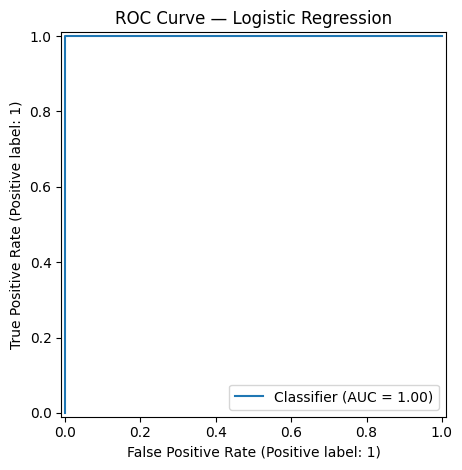

In [26]:
RocCurveDisplay.from_predictions(y_test, best_score)
plt.title(f'ROC Curve — {best_model_name}')
plt.tight_layout()
plt.savefig('outputs/best_model_roc_curve.png', dpi=300)
plt.show()

### Part 2 discussion

After training multiple classification models, most of them achieved extremely high performance, with several reaching near-perfect or perfect scores. Logistic Regression was selected as the best model due to its perfect ROC-AUC and overall simplicity compared to more complex models. While these results strongly support the predictive power of the selected biomarkers, the near-perfect performance may also reflect the reduced and balanced dataset created through random under-sampling.

# Part 3 — External Validation Using GEO/GSE75214

GSE75214 is used here as an external cohort to test whether the pipeline transfers to independent data. The reference study used GSE75214 as its IBD discovery cohort.

Because the main dataset is breast cancer and GSE75214 is an IBD cohort, direct biological validation is limited. This section prepares the GEO cohort and validates the model on any biomarkers shared by both datasets.

## 18. Download or Load GEO Validation Data

Option A: If you already downloaded and prepared the validation data, place it as:

- `GSE75214_X.csv`
- `GSE75214_y.csv`

Option B: Use the GEO download code below. Depending on the environment, you may need internet access and the `GEOparse` package.

In [35]:
import pandas as pd

geo_df = pd.read_csv(
    "GSE75214_series_matrix.txt",
    sep="\t",
    skiprows=66
)

print(geo_df.shape)
geo_df.head()
# Remove possible GEO end marker if present
geo_df = geo_df[geo_df["ID_REF"] != "!series_matrix_table_end"]

# Set probe ID as index and transpose
geo_expr = geo_df.set_index("ID_REF")
X_geo = geo_expr.T

# Convert values to numeric
X_geo = X_geo.apply(pd.to_numeric, errors="coerce")
X_geo = X_geo.fillna(X_geo.median(numeric_only=True))

print("X_geo shape:", X_geo.shape)
X_geo.head()


(33253, 195)
X_geo shape: (194, 33252)


ID_REF,7892501,7892502,7892503,7892504,7892505,7892506,7892507,7892508,7892509,7892510,...,8180409,8180410,8180411,8180412,8180413,8180414,8180415,8180416,8180417,8180418
GSM1426071,3.097244,4.622620,4.588315,9.635181,4.524358,4.125697,5.024878,5.525576,10.967470,4.231957,...,9.958493,10.245059,8.623229,8.106611,8.105194,10.261790,6.833574,5.945972,7.913362,9.946090
GSM1426072,4.459059,4.866747,4.635416,8.897930,4.131027,4.444323,5.808175,4.546079,10.815401,3.943824,...,9.774100,10.464546,8.546375,8.348039,8.242692,10.769426,6.999750,5.603446,8.224295,10.662859
GSM1426073,3.322385,5.793462,7.472632,9.450976,4.633418,4.521593,5.067149,5.147985,9.640120,4.351993,...,8.960292,9.889874,6.911822,8.161219,8.112656,10.497715,6.665201,6.073405,8.193162,10.207571
GSM1426074,4.184156,5.652146,6.024110,8.800208,4.228925,5.214871,5.533964,5.590489,11.459983,4.798000,...,10.514199,10.765940,8.778329,8.443373,8.362471,10.774066,7.196679,5.239702,8.262609,10.451895
GSM1426075,3.567690,5.106890,4.213697,9.105323,4.757025,5.535967,5.146509,4.971026,10.617745,4.105912,...,9.869779,10.678419,7.974683,8.510100,8.446204,11.470899,6.852401,5.874210,8.353227,9.884931


In [36]:
# Save GEO expression matrix
X_geo.to_csv("GSE75214_X.csv", index=False)

print("Saved GSE75214_X.csv")
print(X_geo.shape)

Saved GSE75214_X.csv
(194, 33252)


In [37]:
sample_titles = []

with open("GSE75214_series_matrix.txt", "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("!Sample_title"):
            sample_titles = line.strip().split("\t")[1:]
            break

sample_titles = [s.replace('"', '') for s in sample_titles]

print(len(sample_titles))
print(sample_titles[:10])
y_geo = pd.DataFrame({
    "Sample": [
        "Control" if "control" in s.lower() else "Disease"
        for s in sample_titles
    ]
})

print(y_geo["Sample"].value_counts())

y_geo.to_csv("GSE75214_y.csv", index=False)
print("Saved GSE75214_y.csv")

194
['CD_colon_active_1', 'CD_colon_active_2', 'CD_colon_active_3', 'CD_colon_active_4', 'CD_colon_active_5', 'CD_colon_active_6', 'CD_colon_active_7', 'CD_colon_active_8', 'control_colon_76', 'control_colon_77']
Sample
Disease    172
Control     22
Name: count, dtype: int64
Saved GSE75214_y.csv


## 19. Validate Best Model on External Cohort

This section assumes that the validation files have already been prepared as CSV files.

Important: validation can only use genes that exist in both the training dataset and the validation dataset.

In [38]:
validation_X_path = "GSE75214_X.csv"
validation_y_path = "GSE75214_y.csv"

if os.path.exists(validation_X_path) and os.path.exists(validation_y_path):
    X_val = pd.read_csv(validation_X_path)
    y_val = pd.read_csv(validation_y_path)

    y_val_encoded = LabelEncoder().fit_transform(y_val.iloc[:, 0])
    X_val = X_val.apply(pd.to_numeric, errors='coerce')
    X_val = X_val.fillna(X_val.median(numeric_only=True))
    X_val_log = np.log2(X_val + 1)

    common_biomarkers = [gene for gene in final_biomarkers if gene in X_val_log.columns]
    print("Common biomarkers:", common_biomarkers)

    if len(common_biomarkers) > 0:
        # Re-train using only common biomarkers
        validation_model = trained_models[best_model_name]

        # If the validation cohort does not contain all final biomarkers, retrain on common biomarkers
        if set(common_biomarkers) != set(final_biomarkers):
            validation_model = type(best_model)(**best_model.get_params())
            validation_model.fit(X_train[common_biomarkers], y_train)
            X_val_model = X_val_log[common_biomarkers]
        else:
            X_val_model = X_val_log[final_biomarkers]

        val_pred = validation_model.predict(X_val_model)

        if hasattr(validation_model, 'predict_proba'):
            val_score = validation_model.predict_proba(X_val_model)[:, 1]
        else:
            val_score = validation_model.decision_function(X_val_model)

        print("External validation results:")
        print("Accuracy:", accuracy_score(y_val_encoded, val_pred))
        print("Precision:", precision_score(y_val_encoded, val_pred, zero_division=0))
        print("Recall:", recall_score(y_val_encoded, val_pred, zero_division=0))
        print("F1:", f1_score(y_val_encoded, val_pred, zero_division=0))
        print("ROC-AUC:", roc_auc_score(y_val_encoded, val_score))
    else:
        print("No overlap between selected biomarkers and validation dataset genes.")
else:
    print("Validation CSV files were not found. Prepare GSE75214_X.csv and GSE75214_y.csv before running this section.")

Common biomarkers: []
No overlap between selected biomarkers and validation dataset genes.


### Part 3 discussion

The external validation step was intended to evaluate whether the selected biomarkers and best-performing model could generalize to an independent GEO cohort (GSE75214). However, during validation, no overlapping biomarkers were found between the breast cancer dataset and the GEO dataset because GSE75214 uses Affymetrix probe IDs instead of gene symbols.

This prevented direct validation of the final model. In addition, GSE75214 is based on an IBD cohort rather than breast cancer samples, so biological comparison between the two datasets is limited. 

# Final Conclusion

This project followed the main machine learning pipeline from the reference paper using the provided breast cancer dataset. Differential gene expression analysis was used to identify genes with significant differences between tumor and normal samples, the volcano plot and heatmap helped visualize these expression patterns.

Four feature selection methods were applied, including Mutual Information, RFECV, Elastic Net, and Gradient Boosting, to identify the most relevant biomarkers. Based on the combined results, 10 final biomarkers were selected for classification.

Several machine learning models were then trained and compared. Logistic Regression achieved the best performance, with perfect classification results on the test set (accuracy, precision, recall, F1-score, and ROC-AUC all equal to 1.00). Overall, the selected biomarkers showed strong predictive power for distinguishing tumor from normal samples.

## Known limitations

- **Data leakage:** differential expression and feature selection were run on all 222 balanced samples *before* the train/test split, so the test set influenced which genes were selected. The perfect test scores (accuracy and ROC-AUC = 1.00) are therefore optimistic and should not be read as expected real-world performance.
- **Small test set:** 78 test samples; a single split gives a high-variance estimate. Repeated stratified cross-validation would be more reliable.
- **External validation not completed:** GSE75214 reports Affymetrix probe IDs, not gene symbols, so no biomarkers overlapped. Probe-to-gene mapping is implemented in notebook 02.